# Express Links · Week 1, step 4: effective resistance R

This notebook measures **how hard it is for information to travel between every pair of roads** on the METR-LA and PEMS-BAY road graphs. The number is called the **effective resistance R**. It is step 1 of the method in proposal 3.1: high R marks the pairs where Graph WaveNet is likely to lose information (over-squashing), and the express-link loop (step 7) later uses R to decide where the 25 new links go.

**What it does, in the order of the plan**

1. Writes the R code and **checks it on the 8-road example** (R(1,8) = 3.0, then 0.75 after adding a link from 1 to 8), plus a set of harder tests.
2. Loads the two road graphs from step 2 (`Coding/data/raw/adj_mx.pkl`, `adj_mx_bay.pkl`), makes them two-way and checks that every sensor is connected.
3. Computes **R for every pair of sensors** on both graphs, and checks the result against four facts that must hold for any correct R.
4. Finds the **bridge-like links** (the links that most of the traffic information has to squeeze through) and the highest-R pairs: the raw material for the step 5 bottleneck report.
5. Draws the figures (R spread, R against distance, a map) and **saves R** so steps 5, 7 and 10 can load it in one line.

**Run it:** Runtime → Run all. A **CPU runtime is enough**; no GPU and no training. The whole notebook takes about a minute.

**Output folder:** `Coding/data/processed/<dataset>/resistance/` (the R files) and `Coding/figures/` (figures). A short summary for the report goes to `Coding/data/processed/resistance_summary.md`.

## Why this step matters (in plain words)

Think of every road link as a **water pipe**, and of information (for example, "a jam is starting") as water.

* Two roads joined by **many routes** are like two tanks joined by many pipes: information flows easily. **Low R.**
* Two roads whose only route goes through **one bridge** are like two tanks joined by one thin pipe: everything has to squeeze through it. **High R.**

Graph WaveNet passes information along the road graph the same way. Where many roads funnel through one link, a warning from the far side gets squeezed together with everything else and is lost before it arrives. That is **over-squashing**, and R is the standard way to measure it (Black et al., 2023; Di Giovanni et al., 2023).

**The 8-road example used to test the code:** two districts of four roads each, joined by a single bridge (4 – 5).

```
  1 ─── 2              6 ─── 8
  │     │              │     │
  3 ─── 4 ──────────── 5 ─── 7
          the bridge
```

* Roads 1 and 2 are on the same side: R = 0.75 (easy).
* Roads 1 and 8 are on opposite sides of the bridge: **R = 3.0** (hard).
* Add a direct link from 1 to 8 and R falls to **0.75**. That shortcut is an **express link**: what the project adds later.

**How this differs from step 3**

| | Step 3 (baseline) | Step 4 (this notebook) |
|---|---|---|
| Looks at | the model and the speed data | the **road map only** |
| Question | does our forecaster work? | **where are the bottlenecks?** |
| Needs a GPU / training | yes, about 3.7 GPU-hours | no, about a minute on a CPU |
| Output | errors (MAE, RMSE, MAPE) | an R value for every pair of sensors |

**How it connects to the other steps**

| Step | What it uses from here |
|---|---|
| **5. Bottleneck report** | R spread, the bridge-like links and the highest-R pairs (sections 10 to 11), together with the spectral regions it adds |
| **7. Express-link loop** | `R` and `Lplus` from `resistance.npz`, and `add_link_update` from section 4 to update R after each added link without recomputing everything |
| **10. Seven graph versions** | "map-only" links = highest R; "same-side" = high ρ but low R; R is the axis that separates them |
| **14. RQ1 tests** | the same functions on the toy city (R across 1, 2, 4 or 8 crossings) |
| **Report, section 3 (Method)** | the equations in section 3 below, and the checks in sections 5, 6 and 9 |

## 1. Connect Google Drive

Same as step 3: the cell finds the shared `Coding` folder whether it is in your own Drive or added to My Drive as a shortcut. Outside Colab (for example on a laptop), set the environment variable `EXPRESS_LINKS_DIR` to your local copy of the `Coding` folder.

In [1]:
import os, sys, glob

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Find the shared 'Coding' folder. It works whether the folder is in your own Drive or is
    # your teammate's folder added to My Drive as a shortcut (Organize -> Add shortcut -> My Drive).
    FOLDER = os.path.join('AdvML_F26_Project_&_Survey_Paper', 'Project', 'Coding')
    ROOTS = ['/content/drive/MyDrive', '/content/drive/.shortcut-targets-by-id', '/content/drive/Shareddrives']
    hits = []
    for root in ROOTS:
        for depth in range(4):                      # the folder may sit up to 3 levels down
            hits += glob.glob(os.path.join(root, *(['*'] * depth), FOLDER))
    hits = sorted(set(h for h in hits if os.path.isdir(os.path.join(h, 'data'))), key=len)
    assert hits, ("Couldn't find the 'Coding' folder. In Google Drive open 'Shared with me', right-click "
                  "'AdvML_F26_Project_&_Survey_Paper' -> Organize -> Add shortcut -> My Drive, then rerun this cell.")
    PROJECT_DIR = hits[0]
else:
    PROJECT_DIR = os.environ.get('EXPRESS_LINKS_DIR', os.getcwd())
    assert os.path.isdir(os.path.join(PROJECT_DIR, 'data')), f'No data/ folder in {PROJECT_DIR}; set EXPRESS_LINKS_DIR.'
print('PROJECT_DIR =', PROJECT_DIR)

# Results are written into the shared folder, so you need Editor access to it
try:
    probe = os.path.join(PROJECT_DIR, '.write_test')
    open(probe, 'w').close(); os.remove(probe)
    print('OK  you can write to this folder')
except OSError:
    raise PermissionError('You can read this folder but not write to it. Ask the owner to share it with you as Editor.')

Mounted at /content/drive
PROJECT_DIR = /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding
OK  you can write to this folder


## 2. Settings

Leave these as they are. The two choices that change the numbers are written down here so the report can state them:

* **`CONDUCTANCE = 'weight'`**: each road link is a pipe whose width is its road-graph weight (the thresholded Gaussian kernel of driving distance from DCRNN, between 0.1 and 1). Close sensors get wide pipes; far ones, thin pipes. The alternative `'unweighted'` gives every link width 1; it is computed too (section 9) as a robustness check.
* **`SYMMETRISE = 'max'`**: R is defined only for two-way graphs, and the road graph is one-way in places (A→B is not the same as B→A). We treat two sensors as linked if either direction is linked, with the larger of the two weights. Graph WaveNet itself keeps both directions separate (forward and backward diffusion); this only affects how R is measured.

Nothing here uses speed data, so there is no risk of the test period leaking in.

In [2]:
import json, time, pickle
import numpy as np
import pandas as pd
from scipy.sparse.csgraph import connected_components, shortest_path

DATASETS = {
    'METR-LA':  dict(adj='adj_mx.pkl',     locations='graph_sensor_locations.csv',     h5='metr-la.h5'),
    'PEMS-BAY': dict(adj='adj_mx_bay.pkl', locations='graph_sensor_locations_bay.csv', h5='pems-bay.h5'),
}

CONDUCTANCE = 'weight'      # 'weight' (main) or 'unweighted' (every link = 1)
SYMMETRISE  = 'max'         # two-way weight = max(A[i,j], A[j,i])
BRIDGE_WEAK = 0.5           # a link with bridge score >= 0.5 carries at least half of the flow between its two ends
BRIDGE_TRUE = 0.999         # bridge score 1 = the only connection between two parts of the map
TOP_PAIRS   = 25            # highest-R pairs to list (same number as the express-link budget K)

# Numbers from step 2 (sensor maps), used to check we read the same graph
EXPECTED = {'METR-LA': dict(sensors=207, two_way_links=1313), 'PEMS-BAY': dict(sensors=325, two_way_links=2079)}

RAW_DIR  = os.path.join(PROJECT_DIR, 'data', 'raw')
OUT_ROOT = os.path.join(PROJECT_DIR, 'data', 'processed')
FIG_DIR  = os.path.join(PROJECT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
for name, f in DATASETS.items():
    for key in ['adj', 'locations']:
        p = os.path.join(RAW_DIR, f[key])
        assert os.path.exists(p), f'Missing {p}. Run the step 2 notebook first (it downloads the road graphs).'
print('Raw files      :', RAW_DIR)
print('R files go to  :', os.path.join(OUT_ROOT, '<dataset>', 'resistance'))
print('Figures go to  :', FIG_DIR)

# Same figure style as steps 2 and 3
import matplotlib.pyplot as plt
SPLIT_COLORS = {'train': '#2a78d6', 'val': '#eb6834', 'test': '#1baf7a'}   # categorical order used in step 2
BLUE_RAMP = ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b']       # "how much" ramp used in step 2
ACCENT = '#eb6834'                                                          # bridge-like links (2nd categorical hue)
INK, MUTED, GRID = '#0b0b0b', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e',
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
})

Raw files      : /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/raw
R files go to  : /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/processed/<dataset>/resistance
Figures go to  : /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/figures


## 3. The maths, in five lines

Write the two-way road graph as a weight matrix **W** (N × N, `W[u,v]` = width of the pipe between sensors u and v, zero if not linked).

1. **Degree and Laplacian.** D is the diagonal matrix of each sensor's total link weight, and **L = D − W**.
2. **Effective resistance** between sensors u and v (Black et al., 2023, Eq. 1):

   **R(u, v) = L⁺[u,u] + L⁺[v,v] − 2 · L⁺[u,v]**

   where L⁺ is the pseudoinverse of L. In pipe terms: push one unit of water in at u, take it out at v, and R is the pressure difference you need.
3. **How we compute L⁺.** For each connected part of the map with n sensors, L⁺ = (L + J/n)⁻¹ − J/n, where J is the n × n matrix of ones. This is exact. We do **not** use `numpy.linalg.pinv` on L: on this graph it can lose accuracy (in testing it broke Foster's theorem below by 0.18), and the check in section 9 would catch it.
4. **Between two parts of the map that are not connected, R is infinite**: no amount of pressure moves water between them.
5. **Bridge score of a link** (u, v) = W[u,v] · R(u,v), always between 0 and 1. It is the share of the flow between u and v that goes through that one link. **1 means the link is a bridge** (cut it and the map falls apart); close to 0 means there are plenty of other routes.

**Facts every correct R must satisfy** (these are the tests in sections 5, 6 and 9):

| Fact | What it says |
|---|---|
| Series | roads in a line add up: a path of k unit links has R = k |
| Parallel | two routes side by side combine like 1/R = 1/R₁ + 1/R₂ |
| Foster's theorem | the bridge scores of all links in a connected part add up to exactly n − 1 |
| Never above the shortest path | R(u,v) ≤ the shortest route from u to v, counting each link as 1 / weight |
| Adding a link never raises R | for any pair (this is why express links can only help the flow) |
| A distance | R is symmetric, zero on the diagonal and obeys the triangle inequality |

**Updating R after one added link (needed by step 7).** Adding a link of weight w between u and v changes L⁺ by a rank-one update (Sherman–Morrison), so the loop never has to recompute from scratch:

L⁺_new = L⁺ − w · (L⁺ b)(L⁺ b)ᵀ / (1 + w · R(u,v)),  with b = e_u − e_v.

## 4. The R code

Five small functions. Step 7 copies them into `resistance.py`, so the same code computes R everywhere in the project.

| Function | What it does |
|---|---|
| `to_undirected(A)` | one-way road graph → two-way weight matrix W, self-links removed |
| `effective_resistance(W)` | R for every pair, plus L⁺ and the connected part of each sensor |
| `resistance_from_pinv(Lplus, labels)` | R from L⁺ (inf between parts that are not connected) |
| `add_link_update(Lplus, labels, u, v, w)` | L⁺ after adding one link, without recomputing (step 7) |
| `bridge_scores(W, R)` | weight × R for every link (1 = a true bridge) |

In [3]:
def to_undirected(A, mode=SYMMETRISE):
    '''Two-way weight matrix from the (one-way) road graph, with self-links removed.'''
    A = np.asarray(A, dtype=np.float64)
    if mode == 'max':
        W = np.maximum(A, A.T)
    elif mode == 'mean':
        W = (A + A.T) / 2
    else:
        raise ValueError(mode)
    W = W.copy()
    np.fill_diagonal(W, 0.0)
    return W


def conductance(W, mode=CONDUCTANCE):
    '''Pipe width of each link: the road-graph weight, or 1 for every link.'''
    return W.copy() if mode == 'weight' else (W > 0).astype(np.float64)


def laplacian_pinv(W):
    '''Exact pseudoinverse L+ of L = D - W, one connected part at a time.

    Returns (Lplus, labels): labels[i] is the connected part sensor i belongs to.
    Entries of Lplus between different parts are 0 (they are never used: R there is inf).'''
    W = np.asarray(W, dtype=np.float64)
    n_parts, labels = connected_components(W > 0, directed=False)
    Lp = np.zeros_like(W)
    for c in range(n_parts):
        idx = np.flatnonzero(labels == c)
        n = len(idx)
        if n == 1:
            continue                                   # an isolated sensor: L is 0, so L+ is 0
        Ws = W[np.ix_(idx, idx)]
        L = np.diag(Ws.sum(1)) - Ws
        J = np.full((n, n), 1.0 / n)
        Lp[np.ix_(idx, idx)] = np.linalg.inv(L + J) - J
    return Lp, labels


def resistance_from_pinv(Lp, labels):
    '''R(u,v) = L+[u,u] + L+[v,v] - 2 L+[u,v]; inf between parts that are not connected.'''
    d = np.diag(Lp)
    R = d[:, None] + d[None, :] - 2 * Lp
    R = np.maximum(R, 0.0)                             # remove -1e-16 rounding noise
    R[labels[:, None] != labels[None, :]] = np.inf
    np.fill_diagonal(R, 0.0)
    return R


def effective_resistance(W):
    '''R for every pair. Returns (R, Lplus, labels).'''
    Lp, labels = laplacian_pinv(W)
    return resistance_from_pinv(Lp, labels), Lp, labels


def add_link_update(Lp, labels, u, v, w=1.0):
    '''L+ after adding a two-way link of weight w between u and v (Sherman-Morrison, exact).

    u and v must already be in the same connected part (joining two parts changes the
    part structure; in that case recompute with effective_resistance).'''
    assert labels[u] == labels[v], 'u and v are in different parts: recompute with effective_resistance()'
    x = Lp[:, u] - Lp[:, v]                           # L+ b, with b = e_u - e_v
    r_uv = x[u] - x[v]                                 # = R(u, v) before the link
    return Lp - (w / (1.0 + w * r_uv)) * np.outer(x, x)


def bridge_scores(W, R):
    '''For every link (u < v): weight * R(u,v), the share of the u-v flow that goes through that link.'''
    iu, iv = np.nonzero(np.triu(W > 0, 1))
    return iu, iv, W[iu, iv] * R[iu, iv]

print('OK  R functions defined')

OK  R functions defined


## 5. Test on the 8-road example (the plan's check)

The plan's test for `resistance.py`: **R(1,8) = 3.0, then 0.75 after adding a link from 1 to 8.** Roads are numbered 1 to 8 here, as in the plan; Python counts from 0, so road k is row k − 1.

Why 3.0: inside each district, roads 1 and 4 (and 5 and 8) are joined by two routes of two links each, so R = 1 (two pipes of resistance 2 in parallel); the bridge adds 1; total 1 + 1 + 1 = 3. Adding a direct link of resistance 1 in parallel gives 1 / (1/3 + 1) = 0.75.

(The plan does not draw the 8-road example. This layout passes both of its checks; if the proposal uses another drawing, change `TOY_LINKS` and the two target numbers stay the same.)

In [4]:
TOY_LINKS = [(1, 2), (2, 4), (4, 3), (3, 1),     # district A: a loop 1-2-4-3
             (4, 5),                              # the bridge
             (5, 6), (6, 8), (8, 7), (7, 5)]     # district B: a loop 5-6-8-7

def toy_graph(links, n=8):
    W = np.zeros((n, n))
    for a, b in links:
        W[a - 1, b - 1] = W[b - 1, a - 1] = 1.0
    return W

W_toy = toy_graph(TOY_LINKS)
R_toy, Lp_toy, lab_toy = effective_resistance(W_toy)
r18 = R_toy[0, 7]
assert np.isclose(r18, 3.0), r18
print(f'OK  R(1,8) = {r18:.4f}   (plan: 3.0)')

# Add the express link 1 -> 8 and recompute from scratch
W_toy2 = W_toy.copy(); W_toy2[0, 7] = W_toy2[7, 0] = 1.0
R_toy2, _, _ = effective_resistance(W_toy2)
assert np.isclose(R_toy2[0, 7], 0.75), R_toy2[0, 7]
print(f'OK  after adding the link 1-8: R(1,8) = {R_toy2[0, 7]:.4f}   (plan: 0.75)')

# The fast update (used by step 7) gives exactly the same R
R_fast = resistance_from_pinv(add_link_update(Lp_toy, lab_toy, 0, 7, 1.0), lab_toy)
assert np.allclose(R_fast, R_toy2)
print('OK  the one-link update matches a full recompute')

# The bridge 4-5 is a true bridge (score 1); the loop links are not
iu, iv, bs = bridge_scores(W_toy, R_toy)
score = {(a + 1, b + 1): s for a, b, s in zip(iu, iv, bs)}
assert np.isclose(score[(4, 5)], 1.0) and all(s < 1 for k, s in score.items() if k != (4, 5))
print('OK  the 4-5 link is the only bridge (score 1.00); every loop link scores 0.75')

pd.set_option('display.precision', 2)
print('\nR between every pair of roads (before the express link):')
print(pd.DataFrame(R_toy, index=range(1, 9), columns=range(1, 9)).round(2).to_string())

OK  R(1,8) = 3.0000   (plan: 3.0)
OK  after adding the link 1-8: R(1,8) = 0.7500   (plan: 0.75)
OK  the one-link update matches a full recompute
OK  the 4-5 link is the only bridge (score 1.00); every loop link scores 0.75

R between every pair of roads (before the express link):
      1     2     3     4     5     6     7     8
1  0.00  0.75  0.75  1.00  2.00  2.75  2.75  3.00
2  0.75  0.00  1.00  0.75  1.75  2.50  2.50  2.75
3  0.75  1.00  0.00  0.75  1.75  2.50  2.50  2.75
4  1.00  0.75  0.75  0.00  1.00  1.75  1.75  2.00
5  2.00  1.75  1.75  1.00  0.00  0.75  0.75  1.00
6  2.75  2.50  2.50  1.75  0.75  0.00  1.00  0.75
7  2.75  2.50  2.50  1.75  0.75  1.00  0.00  0.75
8  3.00  2.75  2.75  2.00  1.00  0.75  0.75  0.00


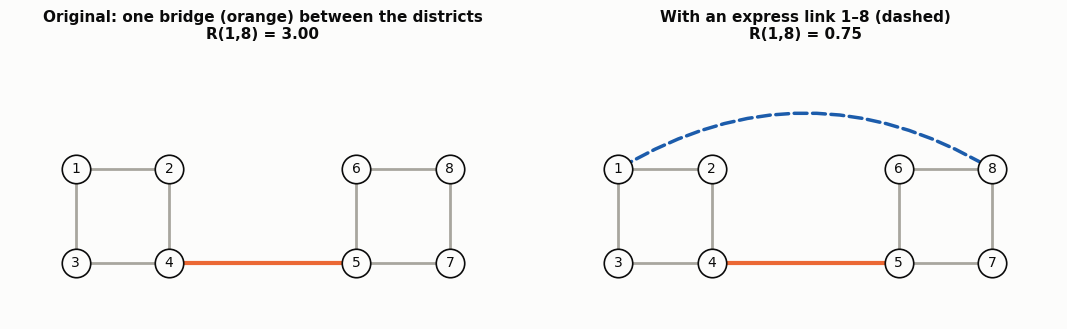

In [5]:
# Figure: the 8-road example before and after the express link
pos = {1: (0, 1), 2: (1, 1), 3: (0, 0), 4: (1, 0), 5: (3, 0), 6: (3, 1), 7: (4, 0), 8: (4, 1)}

def draw_toy(ax, links, R, title, extra=None):
    for a, b in links:
        ax.plot(*zip(pos[a], pos[b]), color=ACCENT if {a, b} == {4, 5} else '#a8a69e',
                lw=3 if {a, b} == {4, 5} else 2, zorder=1, solid_capstyle='round')
    if extra:
        a, b = extra
        ax.annotate('', xy=pos[b], xytext=pos[a], zorder=1,
                    arrowprops=dict(arrowstyle='-', color=BLUE_RAMP[3], lw=2.5, ls='--',
                                    connectionstyle='arc3,rad=-0.3'))
    for k, (x, y) in pos.items():
        ax.scatter(x, y, s=420, color='#fcfcfb', edgecolor=INK, lw=1.2, zorder=2)
        ax.text(x, y, str(k), ha='center', va='center', fontsize=10, zorder=3)
    ax.set_title(f'{title}\nR(1,8) = {R[0, 7]:.2f}', fontsize=11)
    ax.set_xlim(-0.7, 4.7); ax.set_ylim(-0.6, 2.3); ax.set_aspect('equal'); ax.axis('off')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
draw_toy(axes[0], TOY_LINKS, R_toy, 'Original: one bridge (orange) between the districts')
draw_toy(axes[1], TOY_LINKS, R_toy2, 'With an express link 1–8 (dashed)', extra=(1, 8))
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'resistance_toy_example.png'), dpi=160, bbox_inches='tight')
plt.show()

## 6. Harder tests (so we can trust it on 207 and 325 sensors)

One example can pass by luck. These tests check the code against answers known by hand, against an independent library (NetworkX), and against the facts in section 3 on random graphs the size of METR-LA. Every line should say `OK`; if any `assert` fails, do not use the R files.

In [6]:
import networkx as nx
rng = np.random.default_rng(0)

# --- Known answers ---------------------------------------------------------------------------
P = np.zeros((6, 6))                                         # a path of 5 unit links
for i in range(5): P[i, i + 1] = P[i + 1, i] = 1
assert np.isclose(effective_resistance(P)[0][0, 5], 5.0)
print('OK  series: a line of 5 unit links has R = 5')

T = np.ones((3, 3)) - np.eye(3)                              # a triangle: 1 link in parallel with 2 in series
assert np.isclose(effective_resistance(T)[0][0, 1], 2 / 3)
print('OK  parallel: a triangle gives R = 1 x 2 / (1 + 2) = 2/3')

n = 10; K = np.ones((n, n)) - np.eye(n)                      # every road linked to every other
assert np.allclose(effective_resistance(K)[0][~np.eye(n, dtype=bool)], 2 / n)
print('OK  complete graph on 10 roads: every R = 2/10')

Wt = np.array([[0, 4.0], [4.0, 0]])                          # a wider pipe has lower resistance
assert np.isclose(effective_resistance(Wt)[0][0, 1], 0.25)
print('OK  weights: one link of weight 4 has R = 1/4')

D = np.zeros((4, 4)); D[0, 1] = D[1, 0] = 1; D[2, 3] = D[3, 2] = 1   # two separate pieces
R_D, _, lab_D = effective_resistance(D)
assert np.isinf(R_D[0, 2]) and np.isclose(R_D[0, 1], 1) and len(set(lab_D)) == 2
print('OK  disconnected roads: R = inf between the two pieces, finite inside each')

# --- Against NetworkX, on a random weighted graph --------------------------------------------
G = nx.connected_watts_strogatz_graph(40, 4, 0.3, seed=1)
for a, b in G.edges: G[a][b]['weight'] = rng.uniform(0.1, 1.0)
Wg = nx.to_numpy_array(G, weight='weight')
R_g = effective_resistance(Wg)[0]
pairs = [(0, 20), (3, 17), (5, 39), (11, 12)]
ref = [nx.resistance_distance(G, a, b, weight='weight', invert_weight=False) for a, b in pairs]
assert np.allclose([R_g[a, b] for a, b in pairs], ref)
print('OK  matches networkx.resistance_distance on a random 40-road graph')

# --- The facts from section 3, on a random graph the size of METR-LA --------------------------
def random_road_like(n=207, k=8, p=0.1, seed=2):
    G = nx.connected_watts_strogatz_graph(n, k, p, seed=seed)
    W = nx.to_numpy_array(G)
    W[W > 0] = rng.uniform(0.1, 1.0, size=(W > 0).sum())
    return np.triu(W, 1) + np.triu(W, 1).T

def check_facts(W, R, labels, name, n_triples=20000):
    N = len(W)
    assert np.allclose(R, R.T) and np.all(np.diag(R) == 0) and np.all(R >= 0), 'not symmetric / bad diagonal'
    iu, iv, bs = bridge_scores(W, R)
    n_parts = len(np.unique(labels))
    assert np.all(bs <= 1 + 1e-9), 'a bridge score is above 1'
    assert np.isclose(bs.sum(), N - n_parts, atol=1e-6), f'Foster: {bs.sum():.6f} vs {N - n_parts}'
    length = np.where(W > 0, 1.0 / np.where(W > 0, W, 1), 0)
    SP = shortest_path(length, method='D', directed=False)
    fin = np.isfinite(R)
    assert np.all(R[fin] <= SP[fin] + 1e-9), 'R above the shortest path'
    a, b, c = rng.integers(0, N, size=(3, n_triples))
    ok = np.isfinite(R[a, c]) & np.isfinite(R[a, b]) & np.isfinite(R[b, c])
    assert np.all(R[a, c][ok] <= R[a, b][ok] + R[b, c][ok] + 1e-9), 'triangle inequality broken'
    return bs.sum(), N - n_parts

Wr = random_road_like()
R_r, Lp_r, lab_r = effective_resistance(Wr)
s, target = check_facts(Wr, R_r, lab_r, 'random')
print(f'OK  random 207-road graph: symmetric, Foster sum {s:.6f} = n - 1 = {target}, '
      f'R <= shortest path, triangle inequality')

# Adding links never raises R, and the fast update matches a full recompute, link after link
Lp_u, W_u = Lp_r.copy(), Wr.copy()
for _ in range(25):                                          # the express-link budget K = 25
    u, v = rng.choice(len(Wr), 2, replace=False)
    w = float(np.median(Wr[Wr > 0]))
    R_before = resistance_from_pinv(Lp_u, lab_r)
    Lp_u = add_link_update(Lp_u, lab_r, u, v, w)
    W_u[u, v] += w; W_u[v, u] += w
    R_after = resistance_from_pinv(Lp_u, lab_r)
    assert np.all(R_after <= R_before + 1e-9)
assert np.allclose(R_after, effective_resistance(W_u)[0], atol=1e-8)
print('OK  25 added links in a row: R never goes up, and the fast update equals a full recompute')

OK  series: a line of 5 unit links has R = 5
OK  parallel: a triangle gives R = 1 x 2 / (1 + 2) = 2/3
OK  complete graph on 10 roads: every R = 2/10
OK  weights: one link of weight 4 has R = 1/4
OK  disconnected roads: R = inf between the two pieces, finite inside each
OK  matches networkx.resistance_distance on a random 40-road graph
OK  random 207-road graph: symmetric, Foster sum 206.000000 = n - 1 = 206, R <= shortest path, triangle inequality
OK  25 added links in a row: R never goes up, and the fast update equals a full recompute


## 7. Load the road graphs

The files are the DCRNN road graphs that step 2 downloaded and step 3 trained on: `(sensor_ids, id_to_index, adj_mx)`, where `adj_mx[i, j]` is the Gaussian-kernel weight of the driving distance **from** sensor i **to** sensor j (weights below 0.1 set to 0; each sensor linked to itself with weight 1).

The checks confirm that we read the same graph as steps 2 and 3: same sensor count, the same number of two-way links that step 2 drew on its sensor map, and (if the raw speed file is there) the same sensor order as the speed data. The order matters: row i of R must be the same sensor as column i of the speed data, or every later step pairs the wrong roads.

In [7]:
def load_adj(name):
    with open(os.path.join(RAW_DIR, DATASETS[name]['adj']), 'rb') as f:
        sensor_ids, id_to_ind, adj = pickle.load(f, encoding='latin1')
    return [str(s) for s in sensor_ids], np.asarray(adj, dtype=np.float64)

def load_locations(name):
    path = os.path.join(RAW_DIR, DATASETS[name]['locations'])
    if name == 'METR-LA':
        loc = pd.read_csv(path)[['sensor_id', 'latitude', 'longitude']]
    else:                                       # the Bay Area file has no header row
        loc = pd.read_csv(path, header=None, names=['sensor_id', 'latitude', 'longitude'])
    loc['sensor_id'] = loc['sensor_id'].astype(str)
    return loc.set_index('sensor_id')

graphs = {}
for name in DATASETS:
    ids, A = load_adj(name)
    loc = load_locations(name).reindex(ids)
    W = to_undirected(A)
    N = len(ids)
    exp = EXPECTED[name]
    n_dir = int(((A > 0) & ~np.eye(N, dtype=bool)).sum())
    one_way = int((((A > 0) != (A.T > 0)) & ~np.eye(N, dtype=bool)).sum() // 2)
    two_way = int((W > 0).sum() // 2)

    print(f'==== {name} ====')
    assert A.shape == (N, N) and N == exp['sensors'], (A.shape, exp)
    print(f'OK  {N} sensors, {A.shape[0]} x {A.shape[1]} weight table')
    assert two_way == exp['two_way_links'], (two_way, exp['two_way_links'])
    print(f'OK  {n_dir:,} one-way links -> {two_way:,} two-way links (step 2 map: {exp["two_way_links"]:,})')
    print(f'    {one_way:,} sensor pairs are linked in one direction only (made two-way for R)')
    print(f'    weights from {A[A > 0].min():.3f} to {A.max():.3f}; {int((np.diag(A) > 0).sum())} self-links removed')
    assert loc['latitude'].notna().all(), 'some sensors have no map position'
    print('OK  every sensor has a map position')

    # Sensor order must match the speed data (the raw .h5 columns) used by steps 2 and 3
    h5 = os.path.join(RAW_DIR, DATASETS[name]['h5'])
    if os.path.exists(h5):
        cols = [str(c) for c in pd.read_hdf(h5).columns]
        assert cols == ids, 'sensor order differs between the road graph and the speed data'
        print('OK  sensor order is the same as in the speed data')
    else:
        print('--  speed file not found here, sensor-order check skipped (step 3 already checked it)')

    graphs[name] = dict(ids=ids, A=A, W=W, loc=loc)
    print()

==== METR-LA ====
OK  207 sensors, 207 x 207 weight table
OK  1,515 one-way links -> 1,313 two-way links (step 2 map: 1,313)
    1,111 sensor pairs are linked in one direction only (made two-way for R)
    weights from 0.100 to 1.000; 207 self-links removed
OK  every sensor has a map position
OK  sensor order is the same as in the speed data

==== PEMS-BAY ====
OK  325 sensors, 325 x 325 weight table
OK  2,369 one-way links -> 2,079 two-way links (step 2 map: 2,079)
    1,789 sensor pairs are linked in one direction only (made two-way for R)
    weights from 0.100 to 1.000; 325 self-links removed
OK  every sensor has a map position
OK  sensor order is the same as in the speed data



## 8. Is every sensor connected?

R is only finite between sensors that are joined by some route. A sensor with **no link to any other sensor** (only its link to itself) is cut off: R from it to everything else is infinite.

Such sensors already exist in the data: in the DCRNN graphs a few sensors are further than the kernel cut-off from every other sensor. Graph WaveNet trains on them anyway, but with the original graph they never receive information from any other road.

**Decision for later steps (write this in the report):** the cut-off sensors keep `R = inf` in the saved files and are flagged in `component` and `isolated`. Step 7 should **leave them out of the candidate pairs**, because an infinite R would make every link to them the top score regardless of traffic. Step 9 scores them like any other road, and step 5 lists them.

In [8]:
for name, g in graphs.items():
    W, ids, loc = g['W'], g['ids'], g['loc']
    n_parts, labels = connected_components(W > 0, directed=False)
    sizes = np.bincount(labels)
    main = int(np.argmax(sizes))
    isolated = np.flatnonzero(sizes[labels] == 1)
    g.update(labels=labels, main=main, isolated=isolated)

    print(f'==== {name} ====')
    print(f'    {n_parts} connected part(s); sizes {sorted(sizes.tolist(), reverse=True)}')
    print(f'    main part: {sizes[main]} of {len(ids)} sensors ({sizes[main] / len(ids):.1%})')
    if len(isolated):
        print(f'    cut-off sensors (no link to any other sensor): {len(isolated)}')
        print(loc.iloc[isolated][['latitude', 'longitude']].assign(row=isolated).to_string())
    small = [c for c in range(n_parts) if 1 < sizes[c] and c != main]
    if small:
        print(f'    other small parts: {[int(sizes[c]) for c in small]} sensors')
    assert sizes[main] >= 0.95 * len(ids), 'the main part has under 95% of the sensors: check the graph file'
    print(f'OK  the main part holds at least 95% of the sensors\n')

==== METR-LA ====
    2 connected part(s); sizes [206, 1]
    main part: 206 of 207 sensors (99.5%)
    cut-off sensors (no link to any other sensor): 1
           latitude  longitude  row
sensor_id                          
717804        34.09    -118.48   26
OK  the main part holds at least 95% of the sensors

==== PEMS-BAY ====
    7 connected part(s); sizes [319, 1, 1, 1, 1, 1, 1]
    main part: 319 of 325 sensors (98.2%)
    cut-off sensors (no link to any other sensor): 6
           latitude  longitude  row
sensor_id                          
400001        37.36    -121.90    0
400017        37.25    -121.95    1
400240        37.26    -121.95   39
400560        37.32    -122.00   77
400677        37.32    -122.05   92
407202        37.36    -121.84  282
OK  the main part holds at least 95% of the sensors



## 9. Compute R for both datasets

Each graph takes well under a second. After computing, the same facts as in section 6 are checked on the **real** graphs:

* symmetric, zero on the diagonal, never negative;
* **Foster's theorem**: the bridge scores add up to exactly (sensors − connected parts). This is the strongest single check: it fails if even a few entries of L⁺ are off;
* never above the shortest route (each link counted as 1 / weight);
* triangle inequality on 20,000 random triples.

R is also computed with every link set to 1 (`R_unweighted`) to see how much the choice of pipe width matters. A Spearman correlation close to 1 means the two agree on **which** pairs are hard to reach, which is what the express-link loop cares about.

In [9]:
from scipy.stats import spearmanr

for name, g in graphs.items():
    print(f'==== {name} ====')
    Wc = conductance(g['W'], CONDUCTANCE)
    t0 = time.time()
    R, Lp, labels = effective_resistance(Wc)
    secs = time.time() - t0
    assert np.array_equal(labels, g['labels'])

    s, target = check_facts(Wc, R, labels, name)
    print(f'OK  computed in {secs:.2f} s; symmetric, zero diagonal, non-negative')
    print(f'OK  Foster: bridge scores add up to {s:.6f} = sensors - parts = {target}')
    print('OK  R never above the shortest route; triangle inequality holds')

    R_unw, _, _ = effective_resistance(conductance(g['W'], 'unweighted'))
    iu = np.triu_indices(len(R), 1)
    fin = np.isfinite(R[iu])
    rho = spearmanr(R[iu][fin], R_unw[iu][fin]).statistic
    print(f'    weighted vs unweighted R: Spearman {rho:.3f} (1 = same ranking of pairs)')

    hops = shortest_path(g['W'] > 0, unweighted=True, directed=False)
    g.update(Wc=Wc, R=R, Lplus=Lp, R_unweighted=R_unw, hops=hops, spearman_unweighted=float(rho), seconds=secs)
    print()

==== METR-LA ====
OK  computed in 0.05 s; symmetric, zero diagonal, non-negative
OK  Foster: bridge scores add up to 205.000000 = sensors - parts = 205
OK  R never above the shortest route; triangle inequality holds
    weighted vs unweighted R: Spearman 0.986 (1 = same ranking of pairs)

==== PEMS-BAY ====
OK  computed in 0.03 s; symmetric, zero diagonal, non-negative
OK  Foster: bridge scores add up to 318.000000 = sensors - parts = 318
OK  R never above the shortest route; triangle inequality holds
    weighted vs unweighted R: Spearman 0.952 (1 = same ranking of pairs)



## 10. What the numbers look like

For each dataset:

* **R spread** over all pairs of sensors in the main part (median and upper percentiles), next to the number of road links between them (hops).
* **Remoteness of each sensor**: its average R to every other sensor in the main part. High = the sensor sits at the far end of a long chain or behind a weak point. This is what the map in section 11 colours.
* **Bridge-like links**: links with bridge score ≥ 0.5, i.e. links that carry at least half of the flow between their two ends. These are the narrow points of the map, and the start of the step 5 bottleneck report.
* **The 25 highest-R pairs** (same number as the express-link budget). These are the pairs a "map-only" graph version (step 10) would link. They tell us where information has furthest to travel, not yet whether the traffic there is related; that is what ρ adds in step 6.

Distances in km are straight-line distances between the sensor positions, for orientation only.

In [10]:
def km_between(loc, a, b):
    lat1, lon1 = np.radians(loc['latitude'].values[a]), np.radians(loc['longitude'].values[a])
    lat2, lon2 = np.radians(loc['latitude'].values[b]), np.radians(loc['longitude'].values[b])
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(h))

summary = {}
for name, g in graphs.items():
    R, W, ids, loc, hops = g['R'], g['Wc'], g['ids'], g['loc'], g['hops']
    main = np.flatnonzero(g['labels'] == g['main'])
    Rm = R[np.ix_(main, main)]
    iu = np.triu_indices(len(main), 1)
    r = Rm[iu]
    h = hops[np.ix_(main, main)][iu]

    # Remoteness of each sensor: average R to the other sensors of the main part
    remote = np.full(len(ids), np.nan)
    remote[main] = Rm.sum(1) / (len(main) - 1)
    g['remoteness'] = remote

    # Bridge-like links
    bi, bj, bs = bridge_scores(W, R)
    links = pd.DataFrame(dict(row_a=bi, row_b=bj, sensor_a=[ids[i] for i in bi], sensor_b=[ids[j] for j in bj],
                              weight=W[bi, bj], R=R[bi, bj], bridge_score=bs,
                              km=km_between(loc, bi, bj))).sort_values('bridge_score', ascending=False)
    g['links'] = links

    # Highest-R pairs in the main part
    order = np.argsort(r)[::-1][:TOP_PAIRS]
    a, b = main[iu[0][order]], main[iu[1][order]]
    top = pd.DataFrame(dict(row_a=a, row_b=b, sensor_a=[ids[i] for i in a], sensor_b=[ids[j] for j in b],
                            R=R[a, b], hops=hops[a, b].astype(int), km=km_between(loc, a, b)))
    g['top_pairs'] = top

    pct = np.percentile(r, [50, 90, 95, 99])
    summary[name] = dict(
        sensors=len(ids), two_way_links=int((g['W'] > 0).sum() // 2),
        connected_parts=int(len(np.unique(g['labels']))), main_part_sensors=int(len(main)),
        cut_off_sensors=[ids[i] for i in g['isolated']],
        conductance=CONDUCTANCE, symmetrise=SYMMETRISE,
        R_median=float(pct[0]), R_p90=float(pct[1]), R_p95=float(pct[2]), R_p99=float(pct[3]), R_max=float(r.max()),
        R_p99_over_median=float(pct[3] / pct[0]),
        hops_median=float(np.median(h)), hops_max=int(h.max()),
        links_bridge_score_ge_0_5=int((bs >= BRIDGE_WEAK).sum()),
        true_bridges=int((bs >= BRIDGE_TRUE).sum()),
        foster_sum=float(bs.sum()),
        spearman_weighted_vs_unweighted=g['spearman_unweighted'],
        seconds=round(g['seconds'], 3),
    )

    s = summary[name]
    print(f'==== {name}  ({len(main)} sensors in the main part, {len(r):,} pairs) ====')
    print(f'R median {s["R_median"]:.2f} | 90% {s["R_p90"]:.2f} | 95% {s["R_p95"]:.2f} | 99% {s["R_p99"]:.2f} | '
          f'max {s["R_max"]:.2f}   (99% / median = {s["R_p99_over_median"]:.1f}x)')
    print(f'road links between two sensors: median {s["hops_median"]:.0f}, max {s["hops_max"]}')
    print(f'links with bridge score >= {BRIDGE_WEAK}: {s["links_bridge_score_ge_0_5"]}; '
          f'true bridges (score 1): {s["true_bridges"]}')
    print('\nMost bridge-like links:')
    print(links.head(10)[['sensor_a', 'sensor_b', 'weight', 'R', 'bridge_score', 'km']].round(3).to_string(index=False))
    print(f'\nThe {TOP_PAIRS} highest-R pairs (first 10):')
    print(top.head(10)[['sensor_a', 'sensor_b', 'R', 'hops', 'km']].round(2).to_string(index=False))
    print()

==== METR-LA  (206 sensors in the main part, 21,115 pairs) ====
R median 1.01 | 90% 2.82 | 95% 5.30 | 99% 6.24 | max 8.92   (99% / median = 6.2x)
road links between two sensors: median 5, max 13
links with bridge score >= 0.5: 18; true bridges (score 1): 0

Most bridge-like links:
sensor_a sensor_b  weight    R  bridge_score   km
  769867   769926    0.88 1.02          0.89 0.93
  764120   763995    0.52 1.51          0.79 2.08
  717825   717823    0.51 1.40          0.72 2.11
  761604   716968    0.66 1.06          0.70 1.66
  774011   717595    0.59 1.18          0.69 1.81
  767609   767585    0.45 1.47          0.66 2.31
  761604   761599    0.65 0.98          0.64 1.56
  717510   717513    0.68 0.92          0.62 1.58
  767610   718076    0.37 1.64          0.61 2.56
  716941   716943    0.99 0.61          0.61 0.25

The 25 highest-R pairs (first 10):
sensor_a sensor_b    R  hops    km
  769867   763995 8.92    11 15.63
  769867   717825 8.55    13 21.50
  763995   769806 8.46    1

## 11. Figures

1. **Spread of R** over all pairs, with the median and the 99th percentile marked. A long right tail means a small set of pairs is much harder to reach than the rest: the pairs express links are meant for.
2. **R against the number of road links between the pair.** R grows with distance, but at the same number of links, pairs whose route crosses a weak point sit well **above** the others. Those high outliers are the bottleneck pairs.
3. **Map**: each sensor coloured by its remoteness (darker = harder to reach from the rest of the map), grey lines for road links, orange for bridge-like links (score ≥ 0.5). Cut-off sensors are drawn as hollow circles.
4. An **interactive map** (HTML) with the same layers; hover a sensor for its id and R values. Open it from `Coding/figures/` in your browser.

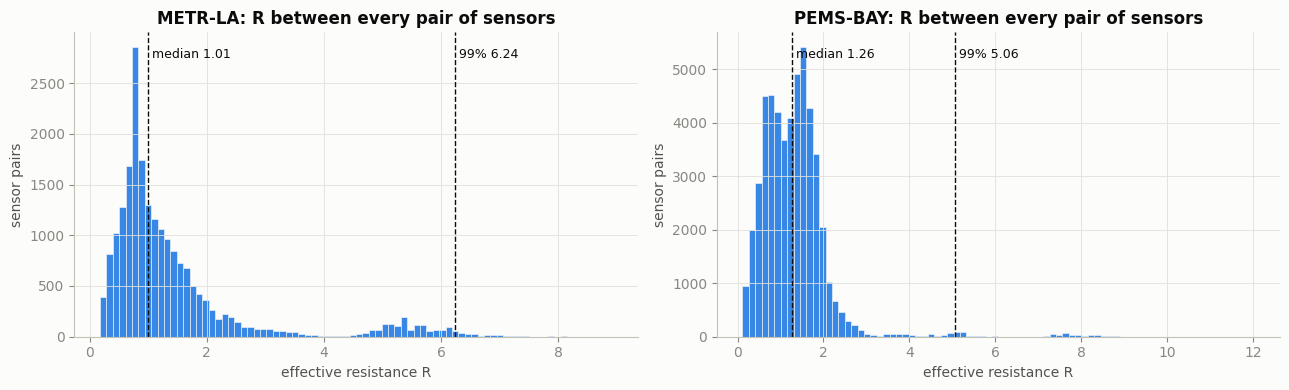

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, g) in zip(axes, graphs.items()):
    main = np.flatnonzero(g['labels'] == g['main'])
    r = g['R'][np.ix_(main, main)][np.triu_indices(len(main), 1)]
    s = summary[name]
    ax.hist(r, bins=80, color=BLUE_RAMP[2], edgecolor='#fcfcfb', linewidth=0.4)
    for val, lab in [(s['R_median'], 'median'), (s['R_p99'], '99%')]:
        ax.axvline(val, color=INK, lw=1, ls='--')
        ax.text(val, ax.get_ylim()[1] * 0.95, f' {lab} {val:.2f}', fontsize=9, va='top')
    ax.set_title(f'{name}: R between every pair of sensors')
    ax.set_xlabel('effective resistance R'); ax.set_ylabel('sensor pairs')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'resistance_histogram.png'), dpi=160, bbox_inches='tight')
plt.show()

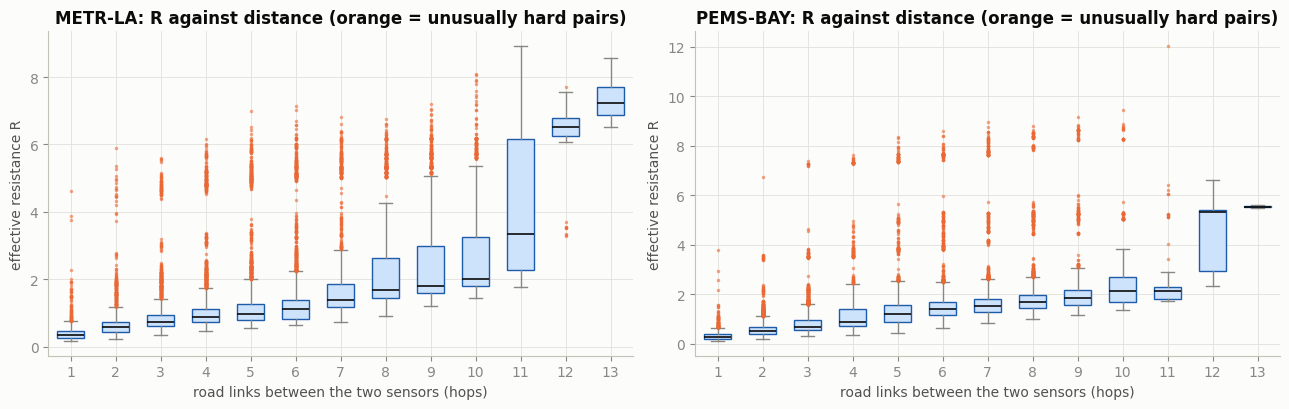

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (name, g) in zip(axes, graphs.items()):
    main = np.flatnonzero(g['labels'] == g['main'])
    iu = np.triu_indices(len(main), 1)
    r = g['R'][np.ix_(main, main)][iu]
    h = g['hops'][np.ix_(main, main)][iu].astype(int)
    df = pd.DataFrame(dict(h=h, r=r))
    groups = [df.r[df.h == k].values for k in range(1, h.max() + 1)]
    bp = ax.boxplot(groups, positions=range(1, h.max() + 1), widths=0.6, showfliers=True, patch_artist=True,
                    medianprops=dict(color=INK, lw=1.2), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                    flierprops=dict(marker='o', markersize=2.5, markerfacecolor=ACCENT, markeredgecolor='none', alpha=0.6))
    for patch in bp['boxes']:
        patch.set(facecolor=BLUE_RAMP[0], edgecolor=BLUE_RAMP[3])
    ax.set_title(f'{name}: R against distance (orange = unusually hard pairs)')
    ax.set_xlabel('road links between the two sensors (hops)'); ax.set_ylabel('effective resistance R')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'resistance_vs_hops.png'), dpi=160, bbox_inches='tight')
plt.show()

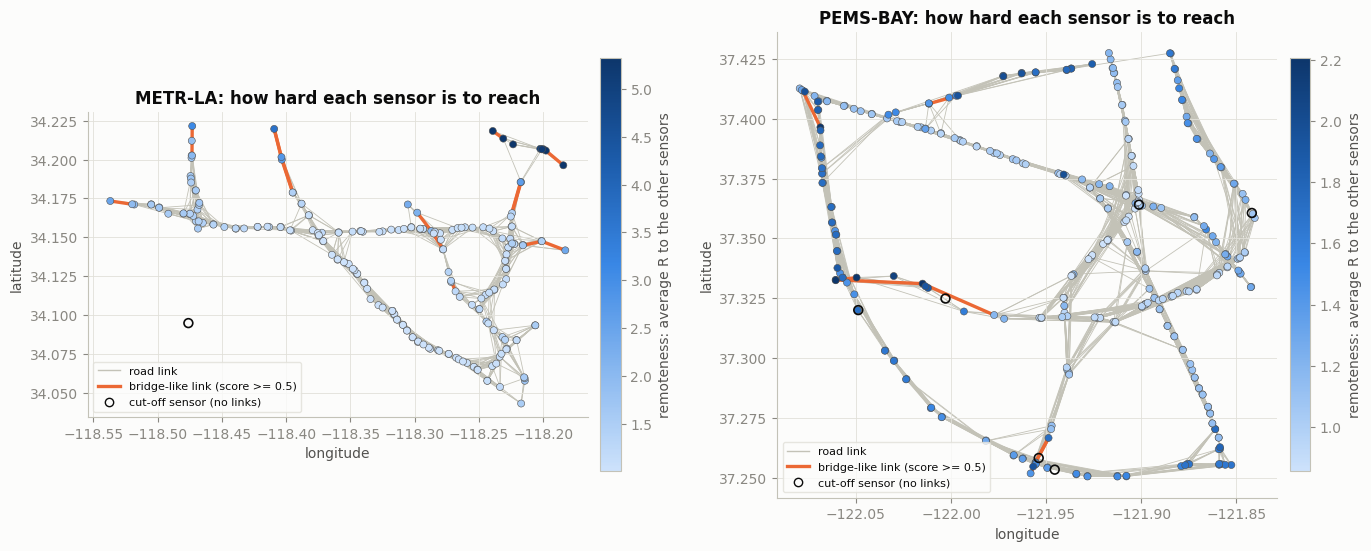

In [13]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
CMAP = LinearSegmentedColormap.from_list('blue_ramp', BLUE_RAMP)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for ax, (name, g) in zip(axes, graphs.items()):
    loc, W, links = g['loc'], g['W'], g['links']
    lat, lon = loc['latitude'].values, loc['longitude'].values
    for i, j in zip(*np.nonzero(np.triu(W > 0, 1))):
        ax.plot([lon[i], lon[j]], [lat[i], lat[j]], color='#c3c2b7', lw=0.6, zorder=1)
    weak = links[links.bridge_score >= BRIDGE_WEAK]
    for i, j in zip(weak.row_a, weak.row_b):
        ax.plot([lon[i], lon[j]], [lat[i], lat[j]], color=ACCENT, lw=2.4, zorder=2, solid_capstyle='round')
    rem = g['remoteness']
    ok = np.isfinite(rem)
    norm = Normalize(np.nanpercentile(rem, 2), np.nanpercentile(rem, 98))
    sc = ax.scatter(lon[ok], lat[ok], c=rem[ok], cmap=CMAP, norm=norm, s=26, edgecolor='#52514e', lw=0.4, zorder=3)
    ax.scatter(lon[~ok], lat[~ok], s=40, facecolor='none', edgecolor=INK, lw=1.2, zorder=3)
    cb = fig.colorbar(sc, ax=ax, shrink=0.7, pad=0.02)
    cb.set_label('remoteness: average R to the other sensors')
    ax.set_aspect(1 / np.cos(np.radians(np.nanmean(lat))))
    ax.set_title(f'{name}: how hard each sensor is to reach')
    ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
    ax.legend(handles=[Line2D([], [], color='#c3c2b7', lw=1, label='road link'),
                       Line2D([], [], color=ACCENT, lw=2.4, label=f'bridge-like link (score >= {BRIDGE_WEAK})'),
                       Line2D([], [], marker='o', ls='', markerfacecolor='none', markeredgecolor=INK,
                              label='cut-off sensor (no links)')],
              loc='lower left', fontsize=8, frameon=True, facecolor='#fcfcfb', edgecolor=GRID)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'resistance_map.png'), dpi=160, bbox_inches='tight')
plt.show()

In [14]:
!pip -q install folium
import folium
from IPython.display import display

TILES = 'https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}'
ATTR = 'Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ'

def ramp_color(value, lo, hi):
    if not np.isfinite(value):
        return '#fcfcfb'
    k = int(np.clip((value - lo) / (hi - lo + 1e-12) * len(BLUE_RAMP), 0, len(BLUE_RAMP) - 1))
    return BLUE_RAMP[k]

def resistance_map(name):
    g = graphs[name]; loc, W, links, rem, ids = g['loc'], g['W'], g['links'], g['remoteness'], g['ids']
    lat, lon = loc['latitude'].values, loc['longitude'].values
    m = folium.Map(tiles=TILES, attr=ATTR, max_zoom=16, control_scale=True)
    m.fit_bounds([[lat.min(), lon.min()], [lat.max(), lon.max()]], padding=(20, 20))
    for i, j in zip(*np.nonzero(np.triu(W > 0, 1))):
        folium.PolyLine([[lat[i], lon[i]], [lat[j], lon[j]]], color='#a8a69e', weight=1, opacity=0.7).add_to(m)
    for _, row in links[links.bridge_score >= BRIDGE_WEAK].iterrows():
        i, j = int(row.row_a), int(row.row_b)
        folium.PolyLine([[lat[i], lon[i]], [lat[j], lon[j]]], color=ACCENT, weight=4, opacity=0.9,
                        tooltip=f'bridge-like link {ids[i]} - {ids[j]}: score {row.bridge_score:.2f}').add_to(m)
    lo, hi = np.nanpercentile(rem, 2), np.nanpercentile(rem, 98)
    for i in np.argsort(np.nan_to_num(rem, nan=np.inf)):
        tip = (f'<b>{name} sensor {ids[i]}</b> (row {i})<br>'
               + (f'remoteness (average R): {rem[i]:.2f}' if np.isfinite(rem[i]) else 'cut off: no links to other sensors'))
        folium.CircleMarker([lat[i], lon[i]], radius=5, color='#52514e', weight=0.8, fill=True, fill_opacity=0.95,
                            fill_color=ramp_color(rem[i], lo, hi), tooltip=tip).add_to(m)
    m.save(os.path.join(FIG_DIR, f'resistance_map_{name}.html'))
    return m

maps = {name: resistance_map(name) for name in graphs}
print('Saved interactive maps:', [f'resistance_map_{n}.html' for n in maps])
display(maps['METR-LA'])

Saved interactive maps: ['resistance_map_METR-LA.html', 'resistance_map_PEMS-BAY.html']


## 12. Save the files

One folder per dataset, `Coding/data/processed/<dataset>/resistance/`, next to the step 2 `train.npz` / `val.npz` / `test.npz`:

| File | Contents |
|---|---|
| `resistance.npz` | `R` (N × N, inf between parts that are not connected), `R_unweighted`, `Lplus` (for the fast update in step 7), `W` (the two-way graph R was computed on), `component` (connected part of each sensor), `isolated` (rows of the cut-off sensors), `remoteness`, `hops`, `sensor_ids` |
| `bridge_links.csv` | every road link with its weight, R and bridge score, most bridge-like first |
| `top_pairs.csv` | the 25 highest-R pairs in the main part |
| `summary.json` | the numbers from section 10 and the settings used |

Rows and columns follow the **sensor order of the road-graph file**, which is the order of the speed data (checked in section 7). The files are reloaded and checked after saving.

In [15]:
for name, g in graphs.items():
    out = os.path.join(OUT_ROOT, name, 'resistance')
    os.makedirs(out, exist_ok=True)
    np.savez_compressed(os.path.join(out, 'resistance.npz'),
                        R=g['R'], R_unweighted=g['R_unweighted'], Lplus=g['Lplus'], W=g['Wc'],
                        component=g['labels'], isolated=g['isolated'], remoteness=g['remoteness'],
                        hops=g['hops'], sensor_ids=np.array(g['ids']))
    g['links'].to_csv(os.path.join(out, 'bridge_links.csv'), index=False)
    g['top_pairs'].to_csv(os.path.join(out, 'top_pairs.csv'), index=False)
    with open(os.path.join(out, 'summary.json'), 'w') as f:
        json.dump(summary[name], f, indent=2)

    # Reload and check
    z = np.load(os.path.join(out, 'resistance.npz'))
    assert np.array_equal(z['R'], g['R']) and np.array_equal(z['Lplus'], g['Lplus'])
    assert list(z['sensor_ids']) == g['ids']
    assert list(z['sensor_ids']) == load_adj(name)[0], 'sensor order changed'
    R_again = resistance_from_pinv(z['Lplus'], z['component'])
    assert np.allclose(R_again, z['R']), 'R cannot be rebuilt from Lplus'
    print(f'OK  {name}: saved and reloaded {out}')
    for fn in sorted(os.listdir(out)):
        print(f'      {fn:20s} {os.path.getsize(os.path.join(out, fn)) / 1e3:8.1f} kB')

OK  METR-LA: saved and reloaded /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/processed/METR-LA/resistance
      bridge_links.csv        128.9 kB
      resistance.npz          967.3 kB
      summary.json              0.6 kB
      top_pairs.csv             1.6 kB
OK  PEMS-BAY: saved and reloaded /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/processed/PEMS-BAY/resistance
      bridge_links.csv        204.7 kB
      resistance.npz         2216.2 kB
      summary.json              0.7 kB
      top_pairs.csv             1.6 kB


## 13. Write down the summary (for the report and the step 5 bottleneck report)

Produces `data/processed/resistance_summary.md` (paste it into the team notes) and `resistance_summary.json`.

In [16]:
lines = ['# Effective resistance summary (Week 1, step 4)', '',
         f'R computed on the two-way road graph (weight = {SYMMETRISE} of the two directions, self-links removed), '
         f'each link conducting {"its road-graph weight" if CONDUCTANCE == "weight" else "1"}. '
         'R uses the road map only, no speed data. Exact pseudoinverse per connected part; '
         "checked against hand-computed examples, NetworkX and Foster's theorem.", '',
         '| | ' + ' | '.join(graphs) + ' |', '|---|' + '---|' * len(graphs)]
rows = [('Sensors', 'sensors', '{:d}'), ('Two-way road links', 'two_way_links', '{:,}'),
        ('Connected parts', 'connected_parts', '{:d}'), ('Sensors in the main part', 'main_part_sensors', '{:d}'),
        ('R, median', 'R_median', '{:.2f}'), ('R, 90th percentile', 'R_p90', '{:.2f}'),
        ('R, 99th percentile', 'R_p99', '{:.2f}'), ('R, maximum', 'R_max', '{:.2f}'),
        ('99th percentile / median', 'R_p99_over_median', '{:.1f}x'),
        ('Road links between two sensors, median / max', None, None),
        (f'Links with bridge score >= {BRIDGE_WEAK}', 'links_bridge_score_ge_0_5', '{:d}'),
        ('True bridges (score 1)', 'true_bridges', '{:d}'),
        ('Spearman, weighted vs unweighted R', 'spearman_weighted_vs_unweighted', '{:.3f}')]
for label, key, fmt in rows:
    if key is None:
        vals = [f'{s["hops_median"]:.0f} / {s["hops_max"]}' for s in summary.values()]
    else:
        vals = [fmt.format(s[key]) for s in summary.values()]
    lines.append(f'| {label} | ' + ' | '.join(vals) + ' |')
lines += ['']
for name, s in summary.items():
    cut = s['cut_off_sensors']
    lines.append(f'- **{name}**: {len(cut)} cut-off sensor(s) with no link to any other sensor'
                 + (f' ({", ".join(cut)}); R = inf for them, leave them out of the express-link candidates.' if cut else '.'))
lines += ['', 'Bridge score of a link = weight x R across it: the share of the flow between its two ends that '
          'goes through that link (1 = a true bridge). Files: `data/processed/<dataset>/resistance/`.']
report = '\n'.join(lines)

with open(os.path.join(OUT_ROOT, 'resistance_summary.md'), 'w') as f:
    f.write(report)
with open(os.path.join(OUT_ROOT, 'resistance_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)

from IPython.display import Markdown
display(Markdown(report))

# Effective resistance summary (Week 1, step 4)

R computed on the two-way road graph (weight = max of the two directions, self-links removed), each link conducting its road-graph weight. R uses the road map only, no speed data. Exact pseudoinverse per connected part; checked against hand-computed examples, NetworkX and Foster's theorem.

| | METR-LA | PEMS-BAY |
|---|---|---|
| Sensors | 207 | 325 |
| Two-way road links | 1,313 | 2,079 |
| Connected parts | 2 | 7 |
| Sensors in the main part | 206 | 319 |
| R, median | 1.01 | 1.26 |
| R, 90th percentile | 2.82 | 1.95 |
| R, 99th percentile | 6.24 | 5.06 |
| R, maximum | 8.92 | 12.03 |
| 99th percentile / median | 6.2x | 4.0x |
| Road links between two sensors, median / max | 5 / 13 | 5 / 13 |
| Links with bridge score >= 0.5 | 18 | 10 |
| True bridges (score 1) | 0 | 3 |
| Spearman, weighted vs unweighted R | 0.986 | 0.952 |

- **METR-LA**: 1 cut-off sensor(s) with no link to any other sensor (717804); R = inf for them, leave them out of the express-link candidates.
- **PEMS-BAY**: 6 cut-off sensor(s) with no link to any other sensor (400001, 400017, 400240, 400560, 400677, 407202); R = inf for them, leave them out of the express-link candidates.

Bridge score of a link = weight x R across it: the share of the flow between its two ends that goes through that link (1 = a true bridge). Files: `data/processed/<dataset>/resistance/`.

## 14. How later steps load R

```python
import numpy as np
z = np.load(f'{PROJECT_DIR}/data/processed/METR-LA/resistance/resistance.npz')
R, Lplus, comp, ids = z['R'], z['Lplus'], z['component'], list(z['sensor_ids'])
R[ids.index('773869'), ids.index('767541')]      # R between two sensors, by id
```

**Step 7 (express-link loop).** Score each candidate pair by ρ(u→v) × R(u,v), using only pairs in the main part (`comp[u] == comp[v] == main`, so no infinite R). After adding the best link with weight w (the median existing weight, plan detail 6), update with `Lplus = add_link_update(Lplus, comp, u, v, w)` and `R = resistance_from_pinv(Lplus, comp)`, then pick the next link. Copy the four functions from section 4 into `resistance.py`. Two notes for the method section:

* The express link is **one-way** in the graph file given to Graph WaveNet (plan detail 7), but R treats it as a two-way pipe of weight w, because R is defined only for two-way graphs. Say so.
* Because the two-way graph uses the larger of the two directions, a one-way link u→v of weight w changes R only if w is larger than the existing weight between u and v.

**Step 5 (bottleneck report).** Start from `bridge_links.csv`, `top_pairs.csv`, the map, and the R-against-hops figure. Add the spectral regions (`graph.py`) and count how many high-R pairs sit across a region boundary.

## Done

Send the team the printout of sections 5, 9 and 13 (the toy check, the Foster check and the summary table).

* **Every check says `OK`:** step 4 is done. The R files are in `Coding/data/processed/<dataset>/resistance/`, and the figures in `Coding/figures/` (`resistance_toy_example.png`, `resistance_histogram.png`, `resistance_vs_hops.png`, `resistance_map.png`, `resistance_map_<dataset>.html`).
* **An `assert` fails in section 5 or 6:** the R code itself is wrong; fix it before anything else.
* **An `assert` fails in section 7:** the road-graph file is not the one steps 2 and 3 used; rerun the step 2 notebook.
* **Foster fails in section 9:** the pseudoinverse lost accuracy; check that section 4 was not changed to use `np.linalg.pinv`.

**For the report (Method, section 3):** R as in section 3 above, after Black et al. (2023); computed on the two-way graph with link weights as conductances; cut-off sensors left out of the express-link candidates. **For Experimental setup:** the summary table from section 13.